# T28 -- Phase 3: per-timestamp diagnostics on the real T0-T72 dataset

**Scope.** `iste.phase3_diagnostics.compute_diagnostics_table`, run over the real
73-timestamp T27 grid against the already-computed real Stage III result
(`results/actual_data/stage3_particle_history.npz`, 548 particles x 6 forcing members
x 73 checkpoints). Reuses T14 (`query_particle_slice`), T15
(`build_particle_neighborhood_index`), T16 (`compute_support_map`), and T17
(`find_candidate_peaks`) unmodified throughout -- this task only computes descriptive
statistics over their existing outputs, never a second density/peak algorithm.

**This is the diagnostic layer, not the fix.** T28 only *measures* the particle-
distribution and support/"KDE"-grid behavior across T0-T72 -- the initial-condition
KDE-concentration bias reported by the user should be directly visible below (tight
cluster / high KDE max near T0, growing dispersion / lower KDE max further back). The
actual ranking correction happens in T29-T39, not here.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.phase3_diagnostics import compute_diagnostics_table
from iste.support_features import SupportFeatureConfig
from iste.candidate_extraction import CandidateExtractionConfig

## 1. Load the real cached Stage III result (T27's own cross-checked dataset)

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
assert os.path.exists(history_path), f"expected real cached Stage III result at {history_path}"
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
print(f"loaded real Stage III result: {records.n_records} rows")

t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
print(f"analysis grid (T27): {len(grid)} timestamps, T0={grid[0]}, T72={grid[-1]}")
assert len(grid) == 73

loaded real Stage III result: 240024 rows
analysis grid (T27): 73 timestamps, T0=2019-10-14T23:00:00.000000000, T72=2019-10-11T23:00:00.000000000


## 2. The data-driven candidate-search grid (same convention as the real-data notebook)

In [3]:
import json as _json
spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
print(f"support/candidate-search grid: {len(support_lat_grid)} x {len(support_lon_grid)} points")

support/candidate-search grid: 167 x 140 points


## 3. Compute the full T0-T72 diagnostic table (73 rows)

In [4]:
t0 = time.time()
table = compute_diagnostics_table(
    records, grid,
    support_lat_grid=support_lat_grid, support_lon_grid=support_lon_grid,
    neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    support_config=support_config, extraction_config=extraction_config,
)
t1 = time.time()
print(f"computed diagnostics for {len(table)} timestamps in {t1 - t0:.1f}s")
assert len(table) == 73

computed diagnostics for 73 timestamps in 110.5s


## 4. The Stage-13/T28 diagnostic table

One row per hourly timestamp, `hours_before_observation` = 0..72. This is the exact
diagnostic the user asked for to see whether early-time dominance comes from physical
particle concentration, KDE bandwidth, screening, normalization, initial-condition
bias, or lack of persistence -- columns for those later corrections (persistence,
screening_score, AIS_score, initial_condition_influence, final_score) are not
populated yet (T29-T39); this row only has what T28 itself computes.

In [5]:
header = f"{'hrs_before_obs':>14s} {'n_particles':>11s} {'spread_km':>10s} {'kde_max':>10s} {'hull_km2':>9s} {'entropy':>8s} {'eff_area_km2':>13s} {'n_modes':>8s}"
print(header)
print("-" * len(header))
for k, d in enumerate(table):
    hull_km2 = d.convex_hull_area_m2 / 1e6 if d.convex_hull_area_m2 is not None else float("nan")
    print(f"{k:>14d} {d.n_particles:>11d} {d.spatial_spread_m/1000:>10.3f} {d.kde_max:>10.2f} "
          f"{hull_km2:>9.3f} {d.kde_entropy:>8.3f} {d.kde_effective_area_m2/1e6:>13.3f} {d.n_significant_modes:>8d}")

hrs_before_obs n_particles  spread_km    kde_max  hull_km2  entropy  eff_area_km2  n_modes
------------------------------------------------------------------------------------------
             0        3288      0.915    4745.00     1.698    4.514         8.399        1
             1        3288      0.946    4675.43     4.692    4.622         9.356        1
             2        3288      0.973    4573.32     6.259    4.697        10.089        1
             3        3288      0.995    4411.98     7.785    4.764        10.785        1
             4        3288      1.017    4288.16     9.304    4.824        11.454        1
             5        3288      1.045    4153.03    10.719    4.890        12.228        1
             6        3288      1.074    3961.17    12.765    4.951        13.001        1
             7        3288      1.106    3807.23    13.974    5.012        13.827        1
             8        3288      1.137    3656.80    14.847    5.078        14.756        1

## 5. Diagnosing the reported early-time dominance

Plot each diagnostic vs. hours-before-observation, to see directly whether the pattern
the user described (tight/high-KDE near T0, dispersed/lower-KDE further back) is
actually present in this real dataset.

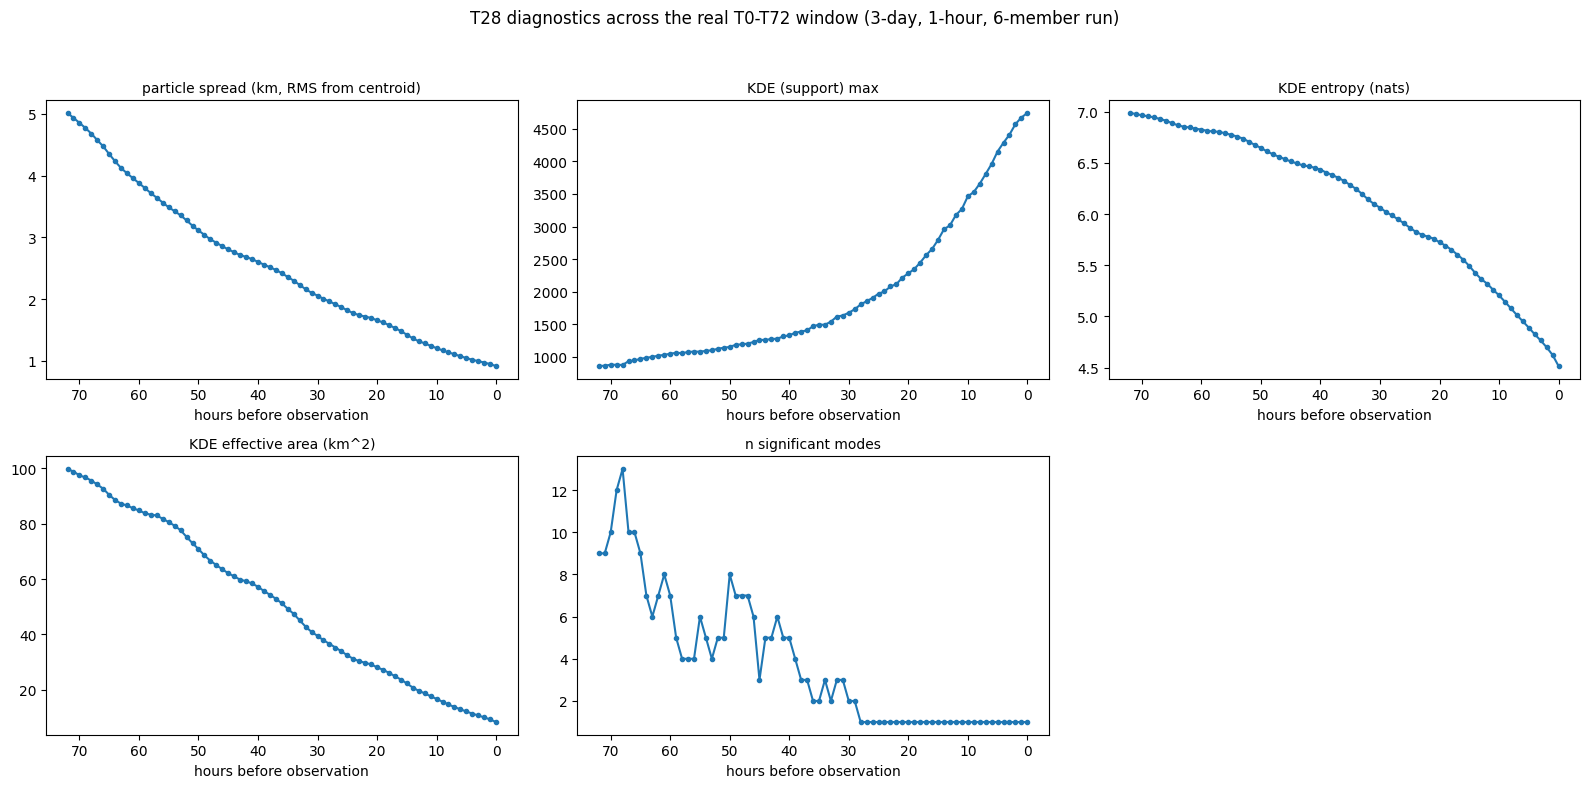

In [6]:
hours = np.arange(len(table))
spread_km = np.array([d.spatial_spread_m / 1000 for d in table])
kde_max = np.array([d.kde_max for d in table])
entropy = np.array([d.kde_entropy for d in table])
eff_area_km2 = np.array([d.kde_effective_area_m2 / 1e6 for d in table])
n_modes = np.array([d.n_significant_modes for d in table])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, (y, label) in zip(axes, [
    (spread_km, "particle spread (km, RMS from centroid)"),
    (kde_max, "KDE (support) max"),
    (entropy, "KDE entropy (nats)"),
    (eff_area_km2, "KDE effective area (km^2)"),
    (n_modes, "n significant modes"),
]):
    ax.plot(hours, y, "-o", markersize=3)
    ax.set_xlabel("hours before observation")
    ax.set_title(label, fontsize=10)
    ax.invert_xaxis()  # T0 (least uncertainty) on the right, T72 on the left
axes[-1].axis("off")
fig.suptitle("T28 diagnostics across the real T0-T72 window (3-day, 1-hour, 6-member run)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T28_diagnostics_t0_t72.png"), dpi=100)
plt.show()

## 6. Explicit finding

In [7]:
corr_spread = float(np.corrcoef(hours, spread_km)[0, 1])
corr_kde = float(np.corrcoef(hours, kde_max)[0, 1])
print(f"correlation(hours_before_obs, spatial_spread_km)  = {corr_spread:+.3f}  (positive = spread grows with age, as expected)")
print(f"correlation(hours_before_obs, kde_max)             = {corr_kde:+.3f}  (negative = KDE max falls with age, as expected)")
print()
print(f"spread_km  at T0={spread_km[0]:.4f}, at T72={spread_km[-1]:.4f}  (ratio {spread_km[-1]/max(spread_km[0],1e-9):.1f}x)")
print(f"kde_max    at T0={kde_max[0]:.2f}, at T72={kde_max[-1]:.2f}")

correlation(hours_before_obs, spatial_spread_km)  = +0.986  (positive = spread grows with age, as expected)
correlation(hours_before_obs, kde_max)             = -0.909  (negative = KDE max falls with age, as expected)

spread_km  at T0=0.9149, at T72=5.0139  (ratio 5.5x)
kde_max    at T0=4745.00, at T72=855.31


## Known limitations (T28 scope only)

- Pure diagnostics -- no normalization (T29), initial-condition correction (T30),
  persistence (T31), convergence (T32), dispersion-aware scoring (T33), screening
  normalization (T34), AIS (T35), composite score (T36), clustering (T37), uncertainty
  (T38), or comparison visualization (T39) is implemented here.
- `kde_entropy`/`kde_effective_area_m2` are descriptive-statistics summaries of the
  normalized, clipped-nonnegative T16 support grid -- explicitly not a claim that
  `Support` is a validated probability density (see this module's own docstring and
  T16's own module docstring).
- `convex_hull_area_m2` is `None` whenever fewer than 3 valid particles exist at a
  timestamp, or the points are exactly collinear -- never fabricated.
- No Stage III module and no T14-T17/T25/T26 module was modified.